# Mini Project: Retail Sales & Customer Analysis

### 1. Data Imports and Inspection

In [67]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

# Set display options: Increase the number of rows and columns shown
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 50)
pd.set_option('display.width', 120)

# Load the dataset
data = pd.read_csv('mini-project_data.csv')


# Overall Inspection

print("1. FIRST 5 ROWS")
display(data.head())

print("\n2. DATASET SHAPE")
print(data.shape)

print("\n3. COLUMN INFORMATION")
data.info()

print("\n4. STATISTICAL SUMMARY")
display(data.describe())

print("\n5. MISSING VALUES")
display(data.isnull().sum())

print("\n6. DUPLICATE ROWS")
print(data.duplicated().sum())

1. FIRST 5 ROWS


,Order_ID,Order_Date,Customer_ID,Region,Category,Product,Quantity,Unit_Price_INR,Discount_Pct,Sales_INR,Profit_INR,Payment_Method,Order_Status,Shipping_Days,Customer_Rating
0,ORD-00001,2025-06-10,CUST-0083,West,Office Supplies,Stapler,2,156.51,25.0,234.76,41.85,Credit Card,Delivered,3.0,4.0
1,ORD-00002,2025-07-19,CUST-0200,West,Office Supplies,Storage Box,1,732.31,0.0,732.31,255.96,Net Banking,Delivered,4.0,4.0
2,ORD-00003,2025-10-12,CUST-0035,North,Home & Kitchen,Bedsheet,2,748.93,0.0,1497.86,358.57,Credit Card,Cancelled,8.0,4.0
3,ORD-00004,2025-09-08,CUST-0215,North,Technology,Smartphone,1,39811.44,10.0,35830.30,4637.94,UPI,Delivered,3.0,4.0
4,ORD-00005,2025-02-21,CUST-0111,North,Office Supplies,Stapler,1,572.15,15.0,486.33,78.75,UPI,Delivered,3.0,4.0



2. DATASET SHAPE
(1204, 15)

3. COLUMN INFORMATION
<class 'pandas.DataFrame'>
RangeIndex: 1204 entries, 0 to 1203
Data columns (total 15 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Order_ID         1204 non-null   str    
 1   Order_Date       1204 non-null   str    
 2   Customer_ID      1204 non-null   str    
 3   Region           1204 non-null   str    
 4   Category         1204 non-null   str    
 5   Product          1204 non-null   str    
 6   Quantity         1204 non-null   int64  
 7   Unit_Price_INR   1204 non-null   float64
 8   Discount_Pct     1204 non-null   float64
 9   Sales_INR        1204 non-null   float64
 10  Profit_INR       1204 non-null   float64
 11  Payment_Method   1196 non-null   str    
 12  Order_Status     1204 non-null   str    
 13  Shipping_Days    1192 non-null   float64
 14  Customer_Rating  1186 non-null   float64
dtypes: float64(6), int64(1), str(8)
memory usage: 141.2 KB

4. STATIS

,Quantity,Unit_Price_INR,Discount_Pct,Sales_INR,Profit_INR,Shipping_Days,Customer_Rating
count,1204.000000,1204.000000,1204.000000,1204.000000,1204.000000,1192.000000,1186.000000
mean,2.024086,10179.439153,9.331395,18216.349244,2356.272384,4.156040,3.765599
std,1.183954,16667.918391,7.423020,36721.186028,4923.373543,1.802363,1.143994
min,1.000000,42.260000,0.000000,42.260000,-4919.150000,1.000000,1.000000
25%,1.000000,653.175000,0.000000,1148.797500,186.122500,3.000000,3.000000
50%,2.000000,3195.020000,10.000000,4853.960000,631.730000,4.000000,4.000000
75%,3.000000,10587.110000,15.000000,17337.270000,2292.060000,5.000000,5.000000
max,5.000000,84619.770000,25.000000,365557.550000,53884.370000,10.000000,5.000000



5. MISSING VALUES


Order_ID            0
Order_Date          0
Customer_ID         0
Region              0
Category            0
Product             0
Quantity            0
Unit_Price_INR      0
Discount_Pct        0
Sales_INR           0
Profit_INR          0
Payment_Method      8
Order_Status        0
Shipping_Days      12
Customer_Rating    18
dtype: int64


6. DUPLICATE ROWS
4


#### 2. Drop Duplicates

In [68]:
data = data.drop_duplicates()  # Remove duplicate rows if any

print("Dataset shape:", data.shape)
print("Remaining duplicates:", data.duplicated().sum())

Dataset shape: (1200, 15)
Remaining duplicates: 0


### 3. Handling missing values

In [69]:
# fill missing values as unknown in payment method
data["Payment_Method"] = data["Payment_Method"].fillna("Unknown")


# fill missing values as median in shipping days
data["Shipping_Days"] = data["Shipping_Days"].fillna(data["Shipping_Days"].median())

# fill missing values as median in customer rating
data["Customer_Rating"] = data["Customer_Rating"].fillna(data["Customer_Rating"].median())

# check for missing values
print("Missing values after imputation:")
print(data.isnull().sum())

Missing values after imputation:
Order_ID           0
Order_Date         0
Customer_ID        0
Region             0
Category           0
Product            0
Quantity           0
Unit_Price_INR     0
Discount_Pct       0
Sales_INR          0
Profit_INR         0
Payment_Method     0
Order_Status       0
Shipping_Days      0
Customer_Rating    0
dtype: int64


### 4. Convert Order_Date to datetime

In [70]:
data['Order_Date'] = pd.to_datetime(data['Order_Date'])
print(data["Order_Date"].dtype)

datetime64[us]


### 5. Fix categorical inconsistencies

In [71]:
data["Region"] = data["Region"].str.strip().str.title()
data["Category"] = data["Category"].str.strip().str.title()
data["Payment_Method"] = data["Payment_Method"].str.strip().str.title()
data["Payment_Method"] = data["Payment_Method"].replace("Upi", "UPI")       # for keeping UPI conventional

print(data["Region"].unique())
print(data["Category"].unique())
print(data["Payment_Method"].unique())

<StringArray>
['West', 'North', 'South', 'East', 'Central']
Length: 5, dtype: str
<StringArray>
['Office Supplies', 'Home & Kitchen', 'Technology', 'Furniture']
Length: 4, dtype: str
<StringArray>
['Credit Card', 'Net Banking', 'UPI', 'Cash On Delivery', 'Debit Card', 'Unknown']
Length: 6, dtype: str


#### 6. Final data validation

In [72]:
print("Dataset shape:", data.shape)

print("\nMissing values:")
print(data.isnull().sum())

print("\nDuplicate rows:", data.duplicated().sum())

print("\nData types:")
print(data.dtypes)

Dataset shape: (1200, 15)

Missing values:
Order_ID           0
Order_Date         0
Customer_ID        0
Region             0
Category           0
Product            0
Quantity           0
Unit_Price_INR     0
Discount_Pct       0
Sales_INR          0
Profit_INR         0
Payment_Method     0
Order_Status       0
Shipping_Days      0
Customer_Rating    0
dtype: int64

Duplicate rows: 0

Data types:
Order_ID                      str
Order_Date         datetime64[us]
Customer_ID                   str
Region                        str
Category                      str
Product                       str
Quantity                    int64
Unit_Price_INR            float64
Discount_Pct              float64
Sales_INR                 float64
Profit_INR                float64
Payment_Method                str
Order_Status                  str
Shipping_Days             float64
Customer_Rating           float64
dtype: object


#### 7. Save the cleaned dataset

This could be saved at orignal file by using this command;

    data.to_csv("mini-project_data.csv", index=False)

Or this could be done to do that seperately, without modifying the orignal csv;

    data.to_csv("retail_orders_cleaned.csv", index=False)

Not utilizing for future confusion preventions because I am going to save this on the GitHub.

#### 8. Actual EDA

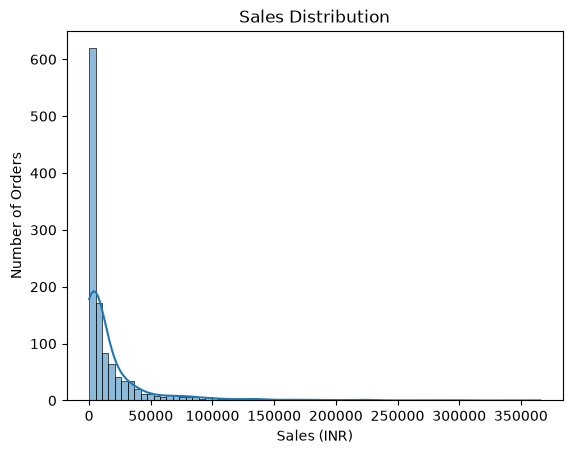

In [73]:
# 1. How are sales distributed across all orders?

sns.histplot(data= data, x = 'Sales_INR', kde = True)

plt.title('Sales Distribution')
plt.xlabel('Sales (INR)')
plt.ylabel('Number of Orders')

plt.show()

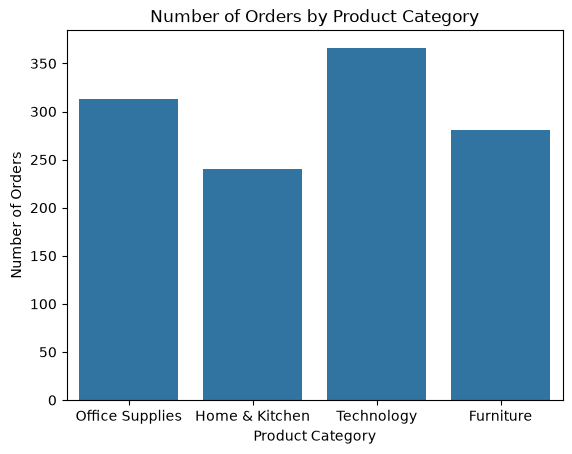

In [74]:
# 2. Product Category Order Count

sns.countplot(data = data, x = "Category")


plt.title('Number of Orders by Product Category')
plt.xlabel('Product Category')
plt.ylabel('Number of Orders')

plt.show()

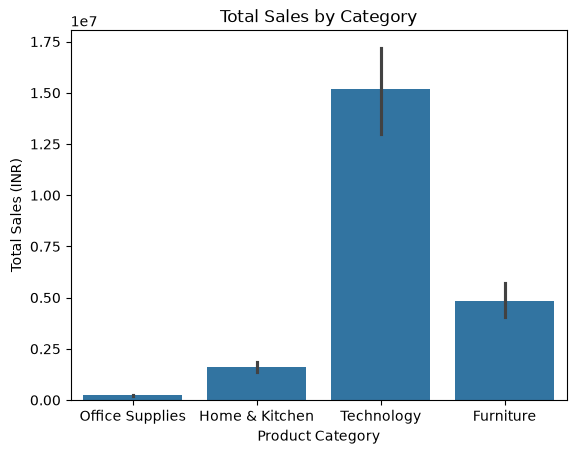

In [75]:
# 3. (a) Total Sales by Category

sns.barplot(data=data, x='Category', y='Sales_INR', estimator='sum')

plt.title('Total Sales by Category')
plt.xlabel('Product Category')
plt.ylabel('Total Sales (INR)')

plt.show()

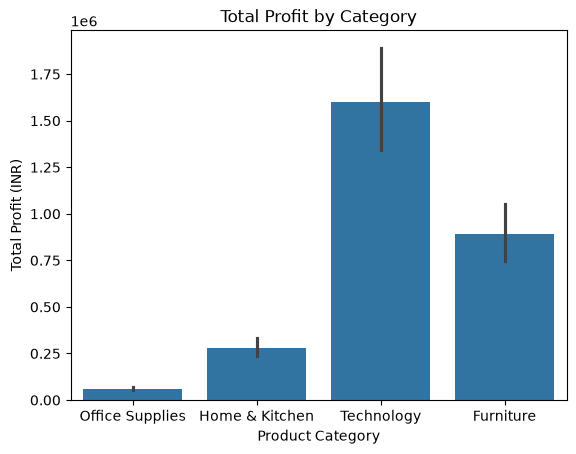

In [76]:
# 3. (b) Total Profit by Category

sns.barplot(data=data, x='Category', y='Profit_INR', estimator='sum')

plt.title('Total Profit by Category')
plt.xlabel('Product Category')
plt.ylabel('Total Profit (INR)')

plt.show()

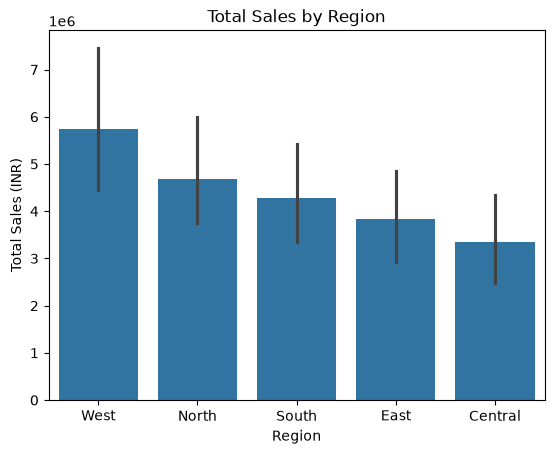

In [77]:
# 4. Regional Sales Performance
# Question: Which region generates the highest total sales?

sns.barplot(data=data, x='Region', y='Sales_INR', estimator='sum')

plt.title('Total Sales by Region')
plt.xlabel('Region')
plt.ylabel('Total Sales (INR)')

plt.show()

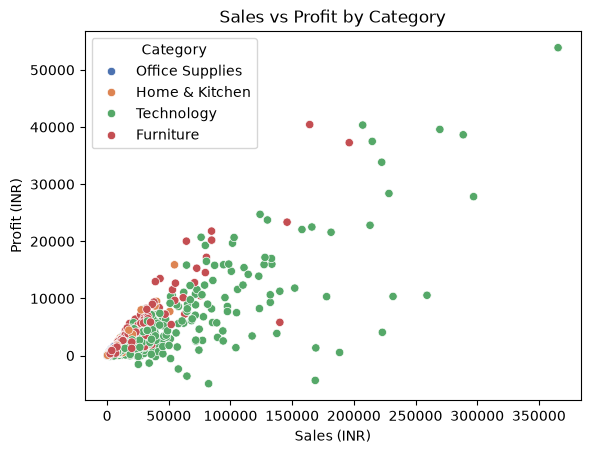

In [78]:
# 5. Relationship Between Sales and Profit
# Question: Do higher-sales orders generally generate higher profits?

sns.scatterplot(
    data=data,
    x='Sales_INR',
    y='Profit_INR',
    hue='Category',
    palette = 'deep'
)

plt.title('Sales vs Profit by Category')
plt.xlabel('Sales (INR)')
plt.ylabel('Profit (INR)')

plt.show()

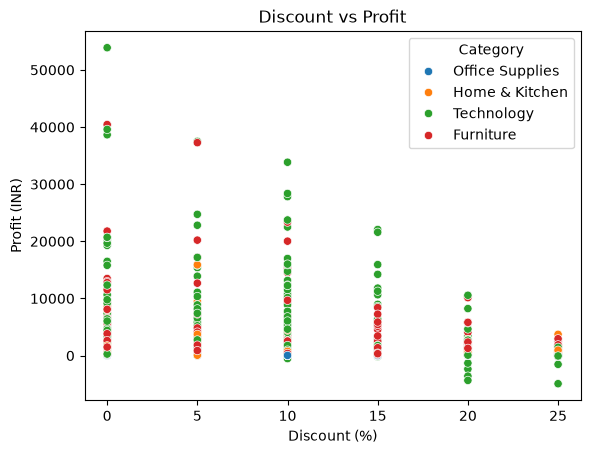

In [79]:
# 6. Discount vs Profit
# Question: Does offering higher discounts affect profitability?

sns.scatterplot(
    data = data,
    x  = 'Discount_Pct',
    y = 'Profit_INR',
    hue = 'Category'
)

plt.title('Discount vs Profit')
plt.xlabel('Discount (%)')
plt.ylabel('Profit (INR)')

plt.show()

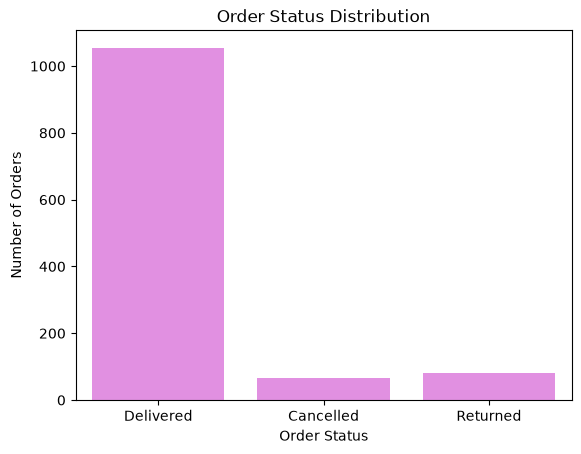

In [80]:
# 7. Order Status Analysis
# Question: How many orders belong to each order status?

sns.countplot(data=data, x='Order_Status', color='violet')

plt.title('Order Status Distribution')
plt.xlabel('Order Status')
plt.ylabel('Number of Orders')

plt.show()

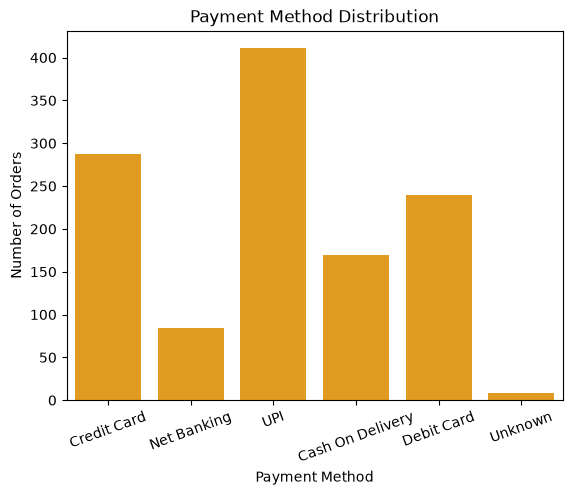

In [81]:
# 8. Payment Method Analysis
# Question: Which payment method is used most frequently?

sns.countplot(data=data, x='Payment_Method', color = 'orange')

plt.title('Payment Method Distribution')
plt.xlabel('Payment Method')
plt.ylabel('Number of Orders')
plt.xticks(rotation=20)

plt.show()

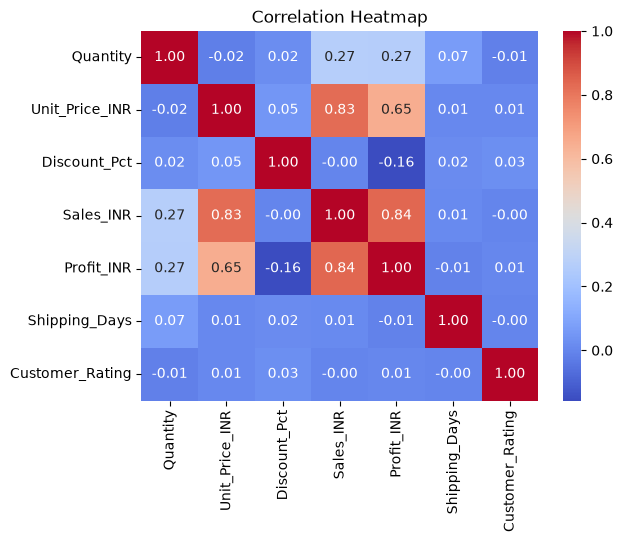

In [82]:
# 9. Correlation Analysis
# Question: Which numerical variables are strongly related to each other?

correlation = data.corr(numeric_only = True)

sns.heatmap(
    correlation,
    annot = True,
    cmap='coolwarm',
    fmt = '.2f'
)

plt.title('Correlation Heatmap')
plt.show()

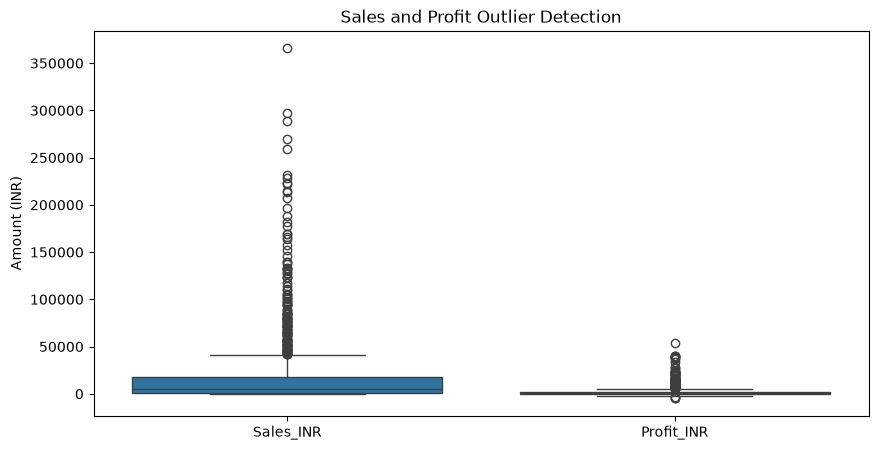

In [83]:
#Identify Outliers
# Question: Are there unusually high or low sales and profit values?

plt.figure(figsize=(10, 5))

sns.boxplot(data=data[['Sales_INR', 'Profit_INR']])

plt.title('Sales and Profit Outlier Detection')
plt.ylabel('Amount (INR)')

plt.show()

## Business Insights & Key Findings

Based on the Exploratory Data Analysis (EDA), the following insights were identified:

1. **Sales Distribution:** Sales are skewed positively, showing that most orders have low sales values, while a few orders are exceptionally high.

2. **Category Performance:** Technology generates the highest total sales and profit among all product categories.

3. **Regional Performance:** The West region has the highest total sales.

4. **Customer Payment Preferences:** UPI is the most frequently used payment method.

5. **Order Status:** Most common order status is 'Delivered'.

6. **Discount and Profitability:** Higher discount levels show more chances of lower profits. Some orders may even turn out to be losses.

7. **Outlier Detection:** Boxplots reveal so many outliers in sales and profit values, including unusually high-value orders.

### Conclusion

The analysis highlights differences in category performance, regional sales, payment preferences and order profitability. Technology is the leading category in both sales and profit, while the West region leads in sales. Discount levels can impact in losses or low profit margins. Also, the unusual order values need further investigation to understand their impact on profitability.

This project demonstrates practical data inspection, cleaning, exploratory analysis and visualization using Python, Pandas, Matplotlib and Seaborn.